# Nested Entanglement Swapping with Dynamical Decoupling

This notebook builds long-distance entanglement the way the original quantum-repeater proposal does
(Briegel, Dür, Cirac, Zoller, 1998): **nested, by doubling**, instead of all swaps at once.

## Parallel vs nested

A chain of 8 links (8 Bell pairs, 16 qubits). Each `=` is a Bell pair (a "link"), each `|` is a place where
two links meet and can be joined by a swap:

```
links:      =  |  =  |  =  |  =  |  =  |  =  |  =  |  =
boundary:      1     2     3     4     5     6     7

PARALLEL (previous notebook): one round
  round 1:  swap at 1 2 3 4 5 6 7 at the same time            -> one link end to end

NESTED (doubling): log2(8) = 3 rounds
  round 1:  swap at 1, 3, 5, 7    8 short links  -> 4 links of length 2
  round 2:  swap at 2, 6          4 links        -> 2 links of length 4
  round 3:  swap at 4             2 links        -> 1 link  of length 8
```

Both schemes use the same Bell pairs and the same 7 Bell measurements, and in an ideal world they give the
**same final state**. The difference is **timing**: in the nested scheme each round is measured and finished
before the next one starts, so the qubits needed in later rounds (and the two end qubits) are **stored**
while earlier rounds run.

## Where dynamical decoupling comes in

While qubits are stored, their phase drifts (the "clock hand" picture). Each round here includes a
**mid-circuit measurement** of the swapped qubits, which takes about 2.6 µs on IBM Heron chips. In a real
network that is the time to measure and send the result to the next station. Every qubit that is still
waiting sits idle during it, so this is exactly where DD can help.

We compare:

| Scheme | What it is |
|---|---|
| `parallel` | all swaps in one round (reference, almost no waiting) |
| `nested` | 1 / 2 / 3 rounds for 2 / 4 / 8 links, no DD |
| `nested + XX` | same, with one X–X pair in every idle gap (a single "echo", as in the earlier DD test) |
| `nested + XX×4` | same, with four X–X pairs in every idle gap (echo every ~0.3 µs, cancels faster drift) |

## What this notebook does not include: purification

In the full BDCZ proposal, after each round the stations **purify** (distil) the links: they take two
noisy copies of a link and turn them into one better link, throwing away the attempt if a check fails. That is
what makes long repeaters work in principle.

It is left out here because each purification step needs **two copies of every link side by side**, with
gates between the copies. IBM chips connect qubits in a sparse honeycomb-like pattern with no such ladders,
so the copies would need many extra SWAP gates, adding more error than purification removes on today's
hardware. Without purification, the nested scheme has no advantage over parallel on a chip; this notebook
measures **how much the extra waiting costs, and how much of it DD can win back**.

## Predictions
- `parallel` ≈ the previous chain results (F ≈ 0.93 / 0.78 / 0.65 for 1 / 3 / 7 swaps).
- `nested` (no DD) is **worse** than parallel, increasingly so with more rounds (more waiting).
- `nested + XX` recovers part of the loss; `nested + XX×4` may recover more if the drift is not too fast.
- With 2 links (1 swap) all schemes are the same circuit (only DD differs), a useful consistency check.
- 16 links (15 swaps, 32 qubits) is probably beyond what the hardware can keep entangled: the chain notebook's
  fit predicted the limit at about 11–12 swaps even for the parallel scheme. It shows where things end up.

## 0. Setup
Uses the same `.env` as the other notebooks.

In [1]:
import json
import os
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import qiskit
import qiskit_ibm_runtime
from dotenv import load_dotenv
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.circuit.library import XGate
from qiskit.primitives import StatevectorSampler
from qiskit.transpiler import PassManager, generate_preset_pass_manager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDelay, PadDynamicalDecoupling
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime import SamplerV2 as Sampler

print("qiskit            ", qiskit.__version__)
print("qiskit-ibm-runtime", qiskit_ibm_runtime.__version__)

qiskit             2.5.2
qiskit-ibm-runtime 0.50.0


In [2]:
load_dotenv()

N_LINKS = [2, 4, 8, 16]           # number of Bell pairs; must be powers of 2 (qubits = 2 * links)
SHOTS = 4000                      # per circuit
DD_VARIANTS = {"XX": 1, "XX×4": 4}  # name -> number of X–X pairs per idle gap
BACKEND_NAME = os.getenv("IBM_BACKEND") or None
SIM_MAX_QUBITS = 16              # ideal local check only up to this size (memory grows as 2^qubits)
EXCLUDE_QUBITS = [137]           # physical qubits never to use (137 read 1 in 83% of shots on 2026-10-16)
READOUT_LIMIT = 0.08             # readout scan: never use qubits whose readout error is above this right now

RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

BASES = ["XX", "YY", "ZZ"]
BELL_LABELS = {"00": "Φ+", "01": "Ψ+", "10": "Φ-", "11": "Ψ-"}  # key = M1 M2
KINDS = ["parallel", "nested"] + [f"nested + {name}" for name in DD_VARIANTS]

n_circuits = len(KINDS) * len(N_LINKS) * len(BASES)
print(f"{n_circuits} circuits in one job, {n_circuits * SHOTS:,} shots, largest chain = {2 * max(N_LINKS)} qubits")

48 circuits in one job, 192,000 shots, largest chain = 32 qubits


## 1. Build the circuits

`swap_rounds` decides which boundaries are swapped in which round. Boundary `b` joins link `b-1` and link `b`
with a Bell measurement on qubits `2b-1` and `2b`, so every swap is still between neighbouring qubits.

Register layout is the same as in the chain notebook: `bsm[2(b-1)]` = m1 and `bsm[2(b-1)+1]` = m2 of the swap
at boundary `b`; `out[0]` = q0, `out[1]` = last qubit. The final correction again only needs the parities
M1 and M2 of all Bell-measurement bits: the order of the swaps does not change it.

`mid_circuit=True` (hardware) measures each round's swapped qubits straight away, before the next round.
`mid_circuit=False` moves all measurements to the end, which gives the same ideal result and lets the local
simulator (which cannot do mid-circuit measurements) check the logic.

2 links: nested rounds = [[1]]
4 links: nested rounds = [[1, 3], [2]]
8 links: nested rounds = [[1, 3, 5, 7], [2, 6], [4]]
16 links: nested rounds = [[1, 3, 5, 7, 9, 11, 13, 15], [2, 6, 10, 14], [4, 12], [8]]


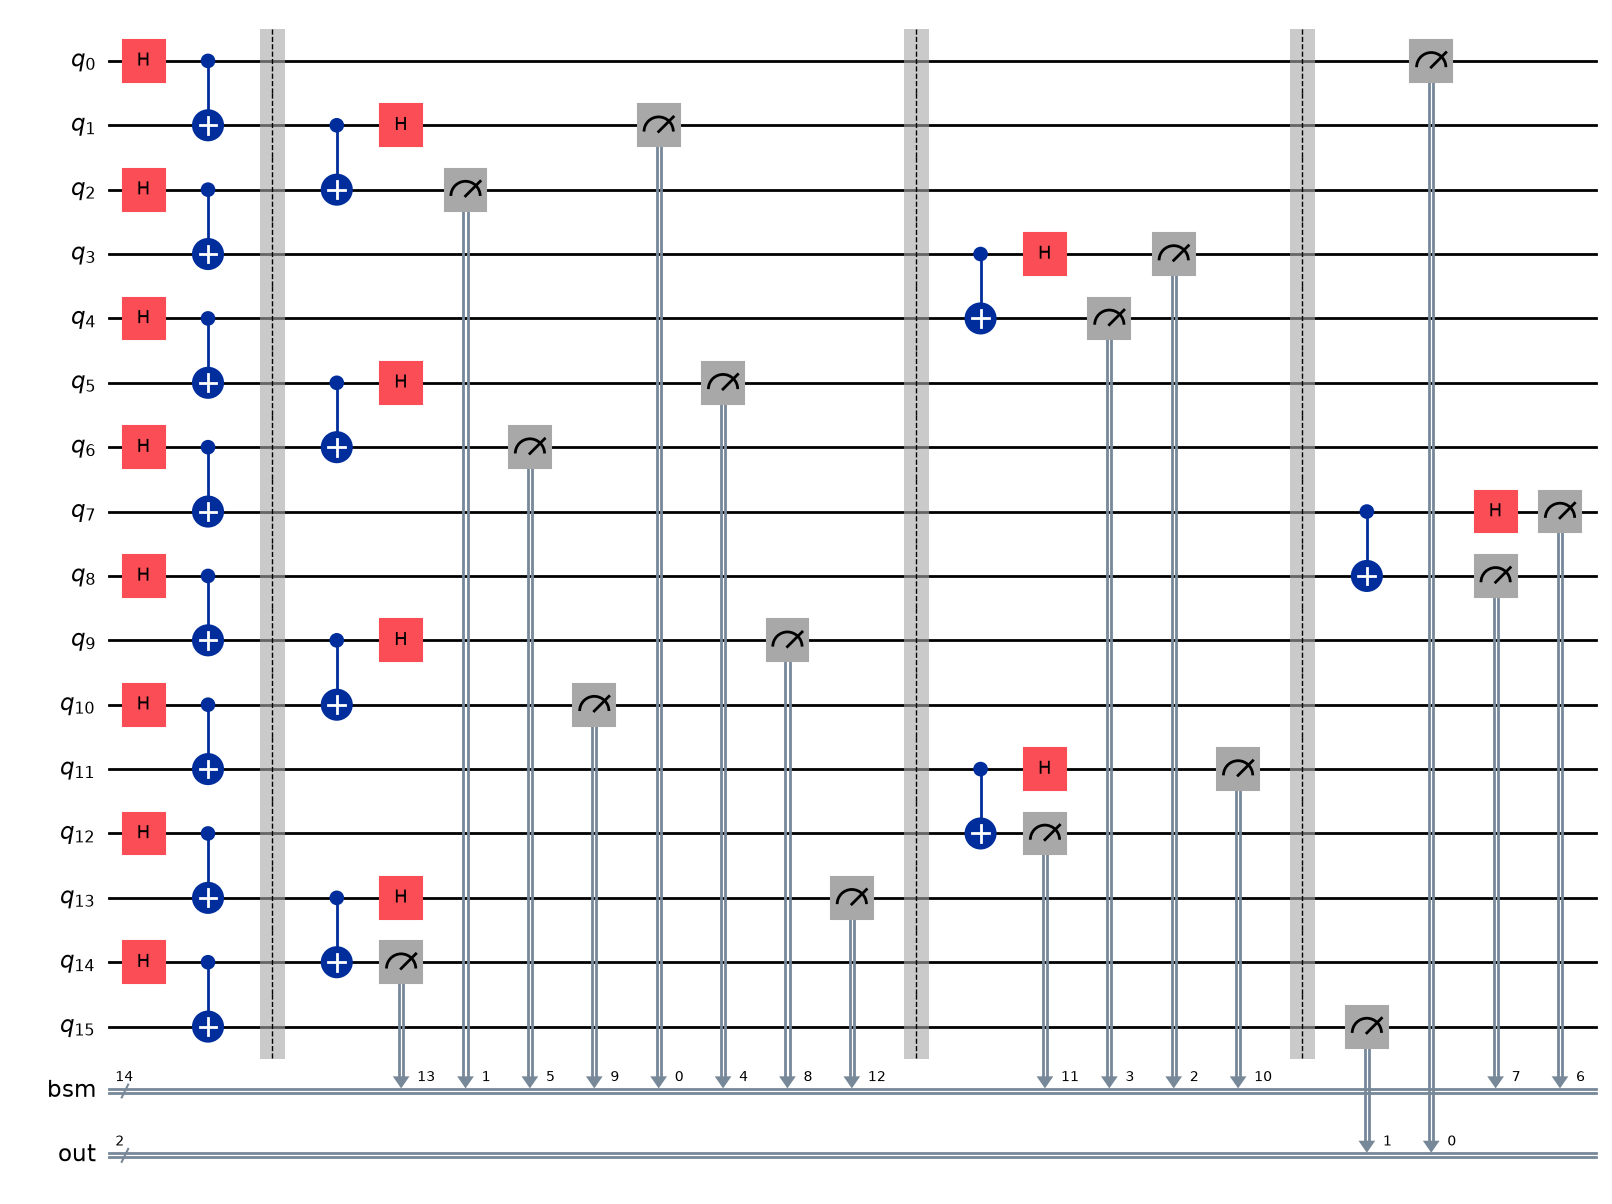

In [3]:
def swap_rounds(n_links, scheme):
    # List of rounds; each round is a list of boundaries b (1 ... n_links-1) swapped in that round.
    boundaries = list(range(1, n_links))
    if scheme == "parallel":
        return [boundaries]
    assert n_links & (n_links - 1) == 0, "nested scheme needs a power-of-2 number of links"
    rounds, level = [], 1
    while 2 ** (level - 1) < n_links:
        rounds.append([b for b in boundaries if b % 2**level == 2 ** (level - 1)])
        level += 1
    return rounds


def add_basis_measurement(qc, basis, qubit):
    # Rotate so that a Z-measurement measures the requested Pauli.
    if basis == "X":
        qc.h(qubit)
    elif basis == "Y":
        qc.sdg(qubit)
        qc.h(qubit)


def build_repeater_circuit(n_links, basis, scheme="nested", mid_circuit=True):
    n_qubits = 2 * n_links
    last = n_qubits - 1
    q = QuantumRegister(n_qubits, "q")
    bsm = ClassicalRegister(2 * (n_links - 1), "bsm")
    out = ClassicalRegister(2, "out")
    qc = QuantumCircuit(q, bsm, out, name=f"{scheme}{n_links}_{basis}")

    # All elementary links (Bell pairs) are created first
    for a in range(0, n_qubits, 2):
        qc.h(a)
        qc.cx(a, a + 1)
    qc.barrier()

    rounds = swap_rounds(n_links, scheme)
    pending = []  # (qubit, clbit) waiting to be measured
    for r, bounds in enumerate(rounds):
        final = r == len(rounds) - 1
        for b in bounds:                       # Bell measurements of this round, in parallel
            qc.cx(2 * b - 1, 2 * b)
            qc.h(2 * b - 1)
            pending += [(2 * b - 1, bsm[2 * (b - 1)]), (2 * b, bsm[2 * (b - 1) + 1])]
        if final:                              # last round: also measure the two end qubits
            add_basis_measurement(qc, basis[0], 0)
            add_basis_measurement(qc, basis[1], last)
            pending += [(0, out[0]), (last, out[1])]
        if mid_circuit or final:
            for qubit, clbit in pending:
                qc.measure(qubit, clbit)
            pending = []
        if not final:
            qc.barrier()                       # next round starts only after this one is finished
    return qc


for n in N_LINKS:
    print(f"{n} links: nested rounds = {swap_rounds(n, 'nested')}")

build_repeater_circuit(8, "ZZ").draw("mpl", fold=-1)

In [4]:
def make_circuits(mid_circuit):
    circs, labs = [], []
    for kind in KINDS:
        scheme = "parallel" if kind == "parallel" else "nested"
        for n in N_LINKS:
            for b in BASES:
                circs.append(build_repeater_circuit(n, b, scheme, mid_circuit=mid_circuit))
                labs.append((kind, n - 1, b))   # analysis is keyed by number of swaps
    return circs, labs


circuits, labels = make_circuits(mid_circuit=True)

## 2. Analysis helpers
Same fidelity formula, correction rules and parity trick as the chain notebook.

In [5]:
CORRECTION_SIGN = {  # basis -> function(M1, M2) -> ±1
    "XX": lambda m1, m2: (-1) ** m1,
    "YY": lambda m1, m2: (-1) ** (m1 + m2),
    "ZZ": lambda m1, m2: (-1) ** m2,
}
BELL_CORRELATORS = {
    "Φ+": {"XX": 1, "YY": -1, "ZZ": 1},
    "Φ-": {"XX": -1, "YY": 1, "ZZ": 1},
    "Ψ+": {"XX": 1, "YY": 1, "ZZ": -1},
    "Ψ-": {"XX": -1, "YY": -1, "ZZ": -1},
}


def joint_counts(pub_result):
    # {"M1M2 ab": count}: M1/M2 = parity of all m1 / m2 bits, a = left end, b = right end
    bsm = pub_result.data.bsm.get_bitstrings()
    out = pub_result.data.out.get_bitstrings()
    counts = defaultdict(int)
    for s_bsm, s_out in zip(bsm, out):
        bits = s_bsm[::-1]                     # little-endian -> bits[i] = bsm[i]
        M1 = bits[0::2].count("1") % 2
        M2 = bits[1::2].count("1") % 2
        counts[f"{M1}{M2} {s_out[::-1]}"] += 1
    return dict(counts)


def _correlator(samples):
    # samples: list of (±1, count) -> (mean, standard error)
    n = sum(c for _, c in samples)
    if n == 0:
        return float("nan"), float("nan")
    mean = sum(v * c for v, c in samples) / n
    return mean, np.sqrt(max(1 - mean**2, 0) / n)


def _fidelity(corr, target):
    f = (1 + sum(target[b] * corr[b][0] for b in BASES)) / 4
    err = np.sqrt(sum(corr[b][1] ** 2 for b in BASES)) / 4
    return f, err


def analyze(counts_by_basis):
    # counts_by_basis: {"XX": joint_counts, "YY": ..., "ZZ": ...}
    per_outcome = {k: {} for k in BELL_LABELS}
    corrected, uncorrected = {}, {}
    for basis in BASES:
        groups = {k: [] for k in BELL_LABELS}
        all_corr, all_raw = [], []
        for key, n in counts_by_basis[basis].items():
            mm, ab = key.split()
            parity = 1 if ab[0] == ab[1] else -1
            groups[mm].append((parity, n))
            all_raw.append((parity, n))
            all_corr.append((CORRECTION_SIGN[basis](int(mm[0]), int(mm[1])) * parity, n))
        for mm in BELL_LABELS:
            per_outcome[mm][basis] = _correlator(groups[mm])
        corrected[basis] = _correlator(all_corr)
        uncorrected[basis] = _correlator(all_raw)

    summary = {}
    for mm, label in BELL_LABELS.items():
        f, e = _fidelity(per_outcome[mm], BELL_CORRELATORS[label])
        summary[f"{label} ({mm})"] = {"F": f, "err": e}
    phi_plus = BELL_CORRELATORS["Φ+"]
    summary["All, corrected"] = dict(zip(("F", "err"), _fidelity(corrected, phi_plus)))
    summary["All, uncorrected"] = dict(zip(("F", "err"), _fidelity(uncorrected, phi_plus)))
    summary["_correlators_corrected"] = {b: corrected[b][0] for b in BASES}
    return summary


def analyze_all(result, run_labels):
    # result + matching labels -> {kind: {n_swaps: summary}}, raw counts alike
    grouped = defaultdict(lambda: defaultdict(dict))
    for pub_result, (kind, n, b) in zip(result, run_labels, strict=True):
        grouped[kind][n][b] = joint_counts(pub_result)
    summaries = {kind: {n: analyze(c) for n, c in by_n.items()} for kind, by_n in grouped.items()}
    counts = {kind: {n: dict(c) for n, c in by_n.items()} for kind, by_n in grouped.items()}
    return summaries, counts


def print_table(title, summaries):
    kinds = [k for k in KINDS if k in summaries]
    ns = sorted(next(iter(summaries.values())))
    print(title)
    print(f"  {'swaps':>5} {'qubits':>6}   " + "   ".join(f"{k:>15}" for k in kinds))
    for n in ns:
        row = []
        for k in kinds:
            s = summaries[k][n]["All, corrected"]
            row.append(f"{s['F']:.3f} ± {s['err']:.3f}")
        print(f"  {n:>5} {2 * n + 2:>6}   " + "   ".join(f"{r:>15}" for r in row))

In [6]:
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]  # categorical slots 1-4, fixed order
INK = "#52514e"


def plot_schemes(summaries, title):
    fig, ax = plt.subplots(figsize=(9, 4.4))
    kinds = [k for k in KINDS if k in summaries]
    ns = sorted(next(iter(summaries.values())))
    for kind, color in zip(kinds, SERIES_COLORS):
        F = [summaries[kind][n]["All, corrected"]["F"] for n in ns]
        E = [summaries[kind][n]["All, corrected"]["err"] for n in ns]
        ax.errorbar(ns, F, yerr=E, color=color, marker="o", markersize=7, linewidth=2, capsize=3, label=kind)
    ax.axhline(0.5, color=INK, linestyle="--", linewidth=1)
    ax.text(min(ns), 0.515, "entanglement threshold F = 0.5", ha="left", va="bottom", color=INK, fontsize=9)
    ax.axhline(0.25, color=INK, linestyle=":", linewidth=1)
    ax.text(min(ns), 0.265, "pure noise F = 0.25", ha="left", va="bottom", color=INK, fontsize=9)
    ax.set_xticks(ns, [f"{k}\n({k + 1} links, {2 * k + 2} q)" for k in ns])
    ax.set_xlabel("number of swaps")
    ax.set_ylabel("Fidelity of the two end qubits")
    ax.set_ylim(0, 1.05)
    ax.set_title(title, loc="left")
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
    ax.set_axisbelow(True)
    ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, -0.22), ncol=4)
    fig.tight_layout()
    return fig

## Part 1: Ideal local simulation

Every scheme should give F = 1 at every length: nesting changes the timing, not the final state.
(These are the `mid_circuit=False` versions, see section 1.) Only chains up to `SIM_MAX_QUBITS` qubits are
simulated, because a statevector simulation needs memory that doubles with every qubit.

IDEAL SIMULATION (corrected F)
  swaps qubits          parallel            nested       nested + XX     nested + XX×4
      1      4     1.000 ± 0.000     1.000 ± 0.000     1.000 ± 0.000     1.000 ± 0.000
      3      8     1.000 ± 0.000     1.000 ± 0.000     1.000 ± 0.000     1.000 ± 0.000
      7     16     1.000 ± 0.000     1.000 ± 0.000     1.000 ± 0.000     1.000 ± 0.000


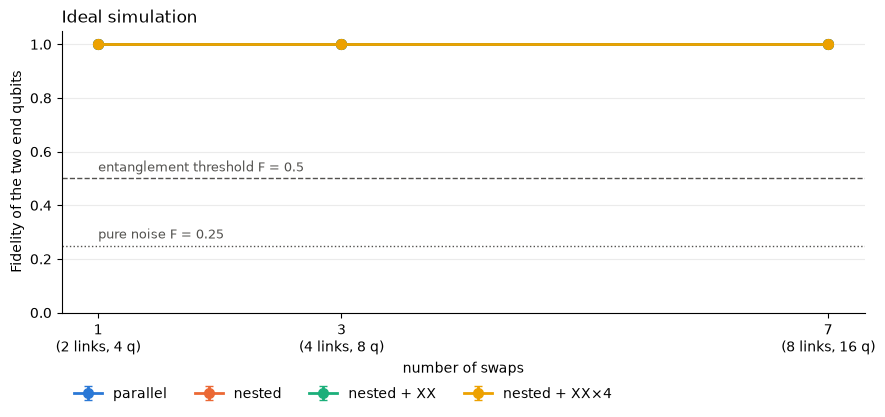

In [7]:
sim_circuits, sim_labels = make_circuits(mid_circuit=False)
keep = [i for i, qc in enumerate(sim_circuits) if qc.num_qubits <= SIM_MAX_QUBITS]
sim_circuits, sim_labels = [sim_circuits[i] for i in keep], [sim_labels[i] for i in keep]
sim_result = StatevectorSampler(seed=1234).run(sim_circuits, shots=SHOTS).result()
sim_summaries, _ = analyze_all(sim_result, sim_labels)
print_table("IDEAL SIMULATION (corrected F)", sim_summaries)
plot_schemes(sim_summaries, "Ideal simulation");

## Part 2: Run on IBM Quantum hardware

### 2a. Connect

In [8]:
token = os.getenv("QISKIT_IBM_TOKEN")
if not token:
    raise RuntimeError("QISKIT_IBM_TOKEN not found — create a .env file (see .env.example)")

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=token,
    instance=os.getenv("QISKIT_IBM_INSTANCE") or None,
)
n_needed = 2 * max(N_LINKS)
if BACKEND_NAME:
    backend = service.backend(BACKEND_NAME)
else:
    backend = service.least_busy(operational=True, simulator=False, min_num_qubits=n_needed)

print(f"Backend: {backend.name}  ({backend.num_qubits} qubits)  pending jobs: {backend.status().pending_jobs}")

qiskit_runtime_service._discover_account:WARNING:2026-10-16 14:48:20,183: Loading account with the given token. A saved account will not be used.


Backend: ibm_marrakesh  (156 qubits)  pending jobs: 0


### 2b. Choose the line of qubits

**Why this step exists:** IBM's calibration data can be out of date. In the run on 2026-10-16 the transpiler
picked qubit 137, which the calibration called fine but which read **1 in 83% of shots** during the job (a
working qubit in these circuits reads 1 about 50% of the time). A later attempt found qubits that were wrong
up to 38% of the time although the calibration said ~1–2%. So the line is chosen from **live** data:

1. **Readout scan of the whole chip:** one tiny job (2 circuits × 1000 shots: every qubit set to 0, then every
   qubit set to 1) measures each qubit's readout error *right now*. Qubits above `READOUT_LIMIT`, and those in
   `EXCLUDE_QUBITS`, are never used.
2. **Best line:** search all lines of the needed length among the remaining qubits and pick the one with the
   lowest total "cost": live readout errors + CZ gate errors + a penalty for qubits that lose coherence quickly
   while stored (`STORE_US / T2`).
3. **Fallback:** if no clean line is long enough for the longest chain, the longest chain is dropped (e.g. 16
   links) and the experiment runs with the remaining nested chains.

In [9]:
import math

STORE_US = 6.0   # typical storage time in the nested scheme, used to weigh T2 in the line choice


def readout_scan(shots=1000):
    # Readout error of every qubit right now: prepare all 0, then all 1, and count wrong answers
    qubits = [q for q in range(backend.num_qubits) if backend.target["measure"].get((q,)) is not None]
    n = len(qubits)
    all0 = QuantumCircuit(n)
    all0.measure_all()
    all1 = QuantumCircuit(n)
    all1.x(range(n))
    all1.measure_all()
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1, initial_layout=qubits)
    res = Sampler(mode=backend).run(pm.run([all0, all1]), shots=shots).result()
    p1_given0 = np.array([[int(c) for c in s[::-1]] for s in res[0].data.meas.get_bitstrings()]).mean(axis=0)
    p0_given1 = 1 - np.array([[int(c) for c in s[::-1]] for s in res[1].data.meas.get_bitstrings()]).mean(axis=0)
    return {qubits[i]: float((p1_given0[i] + p0_given1[i]) / 2) for i in range(n)}


def choose_line(n_qubits, exclude, readout):
    # Lowest-cost simple path of n_qubits physical qubits (branch and bound over the coupling graph)
    t = backend.target
    q_cost = {}
    for q, ro in readout.items():
        props = t.qubit_properties[q] if t.qubit_properties else None
        if q in exclude or props is None or not props.t2:
            continue
        q_cost[q] = -math.log(1 - min(ro, 0.5)) + STORE_US * 1e-6 / props.t2
    e_cost, adj = {}, {q: [] for q in q_cost}
    for (a, b), props in t["cz"].items():
        if a in q_cost and b in q_cost and props is not None and props.error is not None:
            e_cost[frozenset((a, b))] = -math.log(1 - min(props.error, 0.5))
            if b not in adj[a]:
                adj[a].append(b)
                adj[b].append(a)
    if not e_cost:
        return None, math.inf
    floor = min(q_cost.values()) + min(e_cost.values())
    best = [math.inf, None]

    def extend(path, seen, cost):
        if len(path) == n_qubits:
            if cost < best[0]:
                best[:] = [cost, list(path)]
            return
        if cost + (n_qubits - len(path)) * floor >= best[0]:
            return
        last = path[-1]
        options = sorted((e_cost[frozenset((last, nb))] + q_cost[nb], nb) for nb in adj[last] if nb not in seen)
        for step, nb in options:
            path.append(nb)
            seen.add(nb)
            extend(path, seen, cost + step)
            path.pop()
            seen.discard(nb)

    for start in sorted(q_cost, key=q_cost.get):
        extend([start], {start}, q_cost[start])
    return best[1], best[0]


READOUT_SCAN = readout_scan()
bad = {q: e for q, e in READOUT_SCAN.items() if e > READOUT_LIMIT}
excluded = set(EXCLUDE_QUBITS) | set(bad)
errs = np.array(list(READOUT_SCAN.values()))
print(f"Readout scan of {len(READOUT_SCAN)} qubits: median error {np.median(errs):.3f}, "
      f"{len(bad)} above {READOUT_LIMIT:.0%}")
if bad:
    print("  not used:", ", ".join(f"{q} ({e:.0%})" for q, e in sorted(bad.items(), key=lambda x: -x[1])))

LINE = None
while N_LINKS:
    LINE, line_cost = choose_line(2 * max(N_LINKS), excluded, READOUT_SCAN)
    if LINE is not None:
        break
    print(f"No clean line of {2 * max(N_LINKS)} qubits: dropping the {max(N_LINKS)}-link chain")
    N_LINKS = N_LINKS[:-1]
if LINE is None:
    raise RuntimeError("No clean line found even for the shortest chain; try another backend or later")

circuits, labels = make_circuits(mid_circuit=True)   # rebuild in case N_LINKS changed
print(f"\nChains: {N_LINKS} links -> {len(circuits)} circuits, {len(circuits) * SHOTS:,} shots")
print("Physical qubit line:", LINE)
print("readout error now  :", " ".join(f"{READOUT_SCAN[q]:.3f}" for q in LINE))

C:\Users\LOQ\AppData\Local\Temp\ipykernel_3104\599339320.py:55: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  res = Sampler(mode=backend).run(pm.run([all0, all1]), shots=shots).result()


attempt 1: line [12, 13, 14, 15, 19, 35, 34, 33, 39, 53, 52, 51, 50, 49, 48, 47, 46, 45, 44, 43, 42, 41, 36, 21, 22, 23, 16, 3, 4, 5, 6, 7]
           worst readout right now: 0.379   rejected: {39: 0.379, 36: 0.143}
attempt 2: line [89, 88, 87, 97, 107, 106, 105, 104, 103, 96, 83, 84, 85, 77, 65, 64, 63, 56, 43, 44, 45, 46, 47, 48, 49, 50, 51, 52, 53, 54, 55, 59]
           worst readout right now: 0.209   rejected: {83: 0.1485, 85: 0.11799999999999998, 77: 0.11949999999999998, 63: 0.20900000000000002}
attempt 3: line [75, 59, 55, 54, 53, 52, 51, 58, 71, 70, 69, 78, 89, 90, 91, 98, 111, 110, 109, 118, 129, 128, 127, 126, 125, 124, 123, 122, 121, 116, 101, 100]
           worst readout right now: 0.106   rejected: {116: 0.10649999999999998}


RuntimeError: Could not find a clean line in 3 tries; add the rejected qubits to EXCLUDE_QUBITS and retry

### 2c. Transpile and add DD

Every chain uses the start of the line chosen in 2b, so all schemes use the **same physical qubits** and
differences between them come from timing and DD only.

DD is added with `PadDynamicalDecoupling`: in every idle gap long enough to fit it, it inserts the X–X
sequence (1 pair for `XX`, 4 pairs for `XX×4`), spread evenly over the gap. Pulses on a qubit after its last
measurement would do nothing useful, so they are removed.

The table shows, for each circuit, how long the **end qubit q0 is stored** (from the end of its Bell-pair gate
to its measurement) and how many DD pulses were added.

In [ ]:
def drop_pulses_after_last_measure(qc):
    # DD pulses on a qubit after its final measurement have no effect: remove them
    last_meas = {}
    for i, inst in enumerate(qc.data):
        if inst.operation.name == "measure":
            last_meas[inst.qubits[0]] = i
    out = qc.copy()
    out.data = [inst for i, inst in enumerate(qc.data)
                if not (inst.operation.name == "x" and i > last_meas.get(inst.qubits[0], len(qc.data)))]
    return out


def add_dd(isa, repeats):
    pm = PassManager([
        ALAPScheduleAnalysis(target=backend.target),
        PadDynamicalDecoupling(target=backend.target, dd_sequence=[XGate(), XGate()] * repeats),
    ])
    return drop_pulses_after_last_measure(pm.run(isa))


def op_duration(inst, qc):
    op = inst.operation
    if op.name == "barrier":
        return 0.0
    if op.name == "delay":
        return op.duration * backend.target.dt
    qargs = tuple(qc.find_bit(x).index for x in inst.qubits)
    return backend.target[op.name][qargs].duration or 0.0


def storage_time_us(isa, phys_qubit):
    # Time from the end of the qubit's Bell-pair gate to the start of its measurement (ALAP schedule)
    padded = PassManager([ALAPScheduleAnalysis(target=backend.target), PadDelay(target=backend.target)]).run(isa)
    t, after_pair = 0.0, None
    for inst in padded.data:
        if phys_qubit not in (padded.find_bit(x).index for x in inst.qubits):
            continue
        if inst.operation.name == "measure":
            return (t - after_pair) * 1e6
        t += op_duration(inst, padded)
        if after_pair is None and inst.operation.num_qubits == 2:
            after_pair = t
    return float("nan")


def n_x(qc):
    return sum(1 for inst in qc.data if inst.operation.name == "x")


isa_circuits, DD_PULSES = [], {}
for qc, (kind, n, b) in zip(circuits, labels):
    pm = generate_preset_pass_manager(backend=backend, optimization_level=3,
                                      initial_layout=LINE[:qc.num_qubits], seed_transpiler=1234)
    isa = pm.run(qc)
    pulses = 0
    if kind.startswith("nested + "):
        with_dd = add_dd(isa, DD_VARIANTS[kind.removeprefix("nested + ")])
        pulses = n_x(with_dd) - n_x(isa)   # only the X gates DD added (the circuit may contain its own X)
        isa = with_dd
    isa_circuits.append(isa)
    DD_PULSES[f"{kind} | {n} | {b}"] = pulses

print(f"\n{'scheme':<16} {'swaps':>5}   {'q0 stored':>9}   {'DD pulses':>9}   2q gates")
for isa, (kind, n, b) in zip(isa_circuits, labels):
    if b != "ZZ":
        continue
    n_2q = sum(1 for inst in isa.data if inst.operation.num_qubits == 2)
    flag = "" if n_2q == 2 * n + 1 else f"  WARNING: expected {2 * n + 1}"
    print(f"{kind:<16} {n:>5}   {storage_time_us(isa, LINE[0]):>6.2f} µs   {DD_PULSES[f'{kind} | {n} | {b}']:>9}   {n_2q}{flag}")

Physical qubit line: [141, 142, 143, 144, 145, 146, 147, 137, 127, 128, 129, 118, 109, 110, 111, 98]

scheme           swaps   q0 stored   DD pulses   2q gates
parallel             1     0.18 µs           0   3
parallel             3     0.18 µs           0   7
parallel             7     0.18 µs           0   15
nested               1     0.18 µs           0   3
nested               3     3.00 µs           0   7
nested               7     5.82 µs           0   15
nested + XX          1     0.18 µs           4   3
nested + XX          3     3.00 µs          12   7
nested + XX          7     5.82 µs          28   15
nested + XX×4        1     0.18 µs           0   3
nested + XX×4        3     3.00 µs          32   7
nested + XX×4        7     5.82 µs          96   15


### 2d. Submit
All schemes and DD variants go in **one** job, so they run on the same calibration, minutes apart at most.

In [ ]:
sampler = Sampler(mode=backend)
job = sampler.run(isa_circuits, shots=SHOTS)
JOB_ID = job.job_id()

run_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")
(RESULTS_DIR / f"{run_stamp}_{backend.name}_nested_job.txt").write_text(JOB_ID, encoding="utf-8")
print("Submitted job", JOB_ID, "on", backend.name)
print("Track it at https://quantum.cloud.ibm.com/workloads")

C:\Users\LOQ\AppData\Local\Temp\ipykernel_13064\3696504087.py:1: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = Sampler(mode=backend)


Submitted job db97kl424mrc7383job0 on ibm_marrakesh
Track it at https://quantum.cloud.ibm.com/workloads


### 2e. (Optional) Retrieve a previous job
Run sections 0, 1, 2 and 2a (with the same settings as the original job, so `labels` match), then this
cell instead of 2b, 2c and 2d.

In [ ]:
# JOB_ID = "paste-job-id-here"
# job = service.job(JOB_ID)
# backend = job.backend()
# LINE = [...]                  # copy "physical_qubit_line" from the matching *_nested_results.json
# DD_PULSES, READOUT_SCAN, excluded = None, None, set(EXCLUDE_QUBITS)
# run_stamp = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ")

### 2f. Results

HARDWARE (ibm_marrakesh), corrected F
  swaps qubits          parallel            nested       nested + XX     nested + XX×4
      1      4     0.765 ± 0.005     0.778 ± 0.005     0.805 ± 0.005     0.786 ± 0.005
      3      8     0.357 ± 0.007     0.304 ± 0.007     0.318 ± 0.007     0.311 ± 0.007
      7     16     0.378 ± 0.007     0.294 ± 0.007     0.314 ± 0.007     0.288 ± 0.007

Effect of DD on the nested scheme (difference to 'nested' without DD, in standard errors):
  nested + XX      1 swaps: +0.027  (+4.0 SE)
  nested + XX      3 swaps: +0.014  (+1.4 SE)
  nested + XX      7 swaps: +0.020  (+2.1 SE)
  nested + XX×4    1 swaps: +0.008  (+1.2 SE)
  nested + XX×4    3 swaps: +0.007  (+0.7 SE)
  nested + XX×4    7 swaps: -0.005  (-0.5 SE)


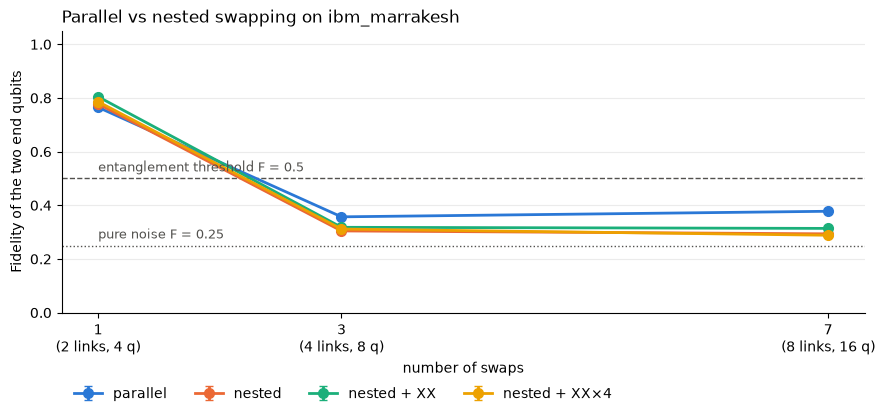

In [ ]:
hw_result = job.result()
hw_summaries, hw_counts = analyze_all(hw_result, labels)
print_table(f"HARDWARE ({backend.name}), corrected F", hw_summaries)

print("\nEffect of DD on the nested scheme (difference to 'nested' without DD, in standard errors):")
for name in DD_VARIANTS:
    kind = f"nested + {name}"
    for n in sorted(hw_summaries["nested"]):
        a = hw_summaries["nested"][n]["All, corrected"]
        b = hw_summaries[kind][n]["All, corrected"]
        diff, se = b["F"] - a["F"], np.hypot(a["err"], b["err"])
        se_txt = f"{diff / se:+.1f} SE" if se > 0 else "-"
        print(f"  {kind:<16} {n} swaps: {diff:+.3f}  ({se_txt})")

fig = plot_schemes(hw_summaries, f"Parallel vs nested swapping on {backend.name}")
fig.savefig(RESULTS_DIR / f"{run_stamp}_{backend.name}_nested_fidelity.png", dpi=150)

### 2g. Per-qubit check

In every circuit here, each measured qubit should read 1 in about **50%** of shots (each is one half of an
entangled pair, or a random Bell-measurement bit). A qubit far from 50% was misbehaving during the job, like
qubit 137 on 2026-10-16. This check flags any qubit off by more than 10 percentage points.

In [ ]:
def qubit_p1(pub_result, n_links):
    # P(measured 1) for each chain position 0 ... 2*n_links-1
    bsm = np.array([[int(c) for c in s[::-1]] for s in pub_result.data.bsm.get_bitstrings()])
    out = np.array([[int(c) for c in s[::-1]] for s in pub_result.data.out.get_bitstrings()])
    nq = 2 * n_links
    p = {0: out[:, 0].mean(), nq - 1: out[:, 1].mean()}
    for k in range(n_links - 1):
        p[2 * k + 1] = bsm[:, 2 * k].mean()
        p[2 * k + 2] = bsm[:, 2 * k + 1].mean()
    return p


QUBIT_P1_WORST = {}   # physical qubit -> P(1) furthest from 0.5 over all circuits
for pub_result, (kind, n, b) in zip(hw_result, labels):
    for pos, p in qubit_p1(pub_result, n + 1).items():
        q = LINE[pos]
        if q not in QUBIT_P1_WORST or abs(p - 0.5) > abs(QUBIT_P1_WORST[q] - 0.5):
            QUBIT_P1_WORST[q] = float(p)

suspects = {q: p for q, p in QUBIT_P1_WORST.items() if abs(p - 0.5) > 0.10}
print("Worst P(1) per qubit:", " ".join(f"{q}:{QUBIT_P1_WORST[q]:.2f}" for q in LINE))
print("Suspicious qubits:", suspects or "none")

In [ ]:
record = {
    "experiment": "entanglement_swapping_nested_dd",
    "timestamp_utc": run_stamp,
    "backend": backend.name,
    "job_id": JOB_ID,
    "shots_per_circuit": SHOTS,
    "n_links": N_LINKS,
    "kinds": KINDS,
    "dd_variants": {name: f"[X, X] x {r} per idle gap (PadDynamicalDecoupling, ALAP)" for name, r in DD_VARIANTS.items()},
    "physical_qubit_line": LINE,
    "excluded_qubits": sorted(excluded),
    "readout_limit": READOUT_LIMIT,
    "readout_scan": READOUT_SCAN,
    "qubit_p1_worst": QUBIT_P1_WORST,
    "dd_pulses": DD_PULSES,
    "qiskit": qiskit.__version__,
    "qiskit_ibm_runtime": qiskit_ibm_runtime.__version__,
    # counts keyed "M1M2 ab" (parities of all Bell-measurement bits, then the two end qubits)
    "counts": {kind: {str(n): c for n, c in by_n.items()} for kind, by_n in hw_counts.items()},
    "summary": {kind: {str(n): s for n, s in by_n.items()} for kind, by_n in hw_summaries.items()},
}
path = RESULTS_DIR / f"{run_stamp}_{backend.name}_nested_results.json"
path.write_text(json.dumps(record, indent=2, ensure_ascii=False), encoding="utf-8")
print("Saved", path)

print("\nLog lines for CLAUDE.md:")
for kind in KINDS:
    for n in sorted(hw_summaries[kind]):
        s = hw_summaries[kind][n]["All, corrected"]
        print(f"| {run_stamp} | {backend.name} | {JOB_ID} | {kind}, {n} swaps ({2 * n + 2} q) | {SHOTS} "
              f"| {s['F']:.3f} ± {s['err']:.3f} | - | |")

Saved results\20261016T192613Z_ibm_marrakesh_nested_results.json

Log lines for CLAUDE.md:
| 20261016T192613Z | ibm_marrakesh | db97kl424mrc7383job0 | parallel, 1 swaps (4 q) | 4000 | 0.765 ± 0.005 | - | |
| 20261016T192613Z | ibm_marrakesh | db97kl424mrc7383job0 | parallel, 3 swaps (8 q) | 4000 | 0.357 ± 0.007 | - | |
| 20261016T192613Z | ibm_marrakesh | db97kl424mrc7383job0 | parallel, 7 swaps (16 q) | 4000 | 0.378 ± 0.007 | - | |
| 20261016T192613Z | ibm_marrakesh | db97kl424mrc7383job0 | nested, 1 swaps (4 q) | 4000 | 0.778 ± 0.005 | - | |
| 20261016T192613Z | ibm_marrakesh | db97kl424mrc7383job0 | nested, 3 swaps (8 q) | 4000 | 0.304 ± 0.007 | - | |
| 20261016T192613Z | ibm_marrakesh | db97kl424mrc7383job0 | nested, 7 swaps (16 q) | 4000 | 0.294 ± 0.007 | - | |
| 20261016T192613Z | ibm_marrakesh | db97kl424mrc7383job0 | nested + XX, 1 swaps (4 q) | 4000 | 0.805 ± 0.005 | - | |
| 20261016T192613Z | ibm_marrakesh | db97kl424mrc7383job0 | nested + XX, 3 swaps (8 q) | 4000 | 0.318 ± 0

## Interpreting the results

- **1 swap (2 links):** parallel and nested are the same circuit. Their F should agree within the error bars;
  if not, the hardware drifted during the job.
- **Nested (no DD) below parallel:** the cost of storing qubits while each round is measured. It grows with
  the number of rounds (1 / 2 / 3 for 2 / 4 / 8 links).
- **Nested + DD above nested:** the part of that storage cost that came from slow phase drift, which the
  X–X echoes cancel. Whatever remains is true decoherence (energy loss T1 and fast random noise).
- **XX×4 vs XX:** more frequent echoes cancel faster drift; if XX×4 is not better, the remaining noise is
  either too fast for this spacing or the extra pulses add as much error as they remove.

On a chip, where all links exist at the same moment, parallel swapping is the best choice. The nested scheme
pays off in real networks only together with purification and with links that appear at random times.